# M16 · 06 — Post-training (A3): general SFT, task SFT, DPO

Decision: `docs/decisions/0025-own-llm-m16.md` §9. Every step starts from the previous one's
`final_model.pt`; the first from the A2 model (`stage-a-110m`, 5B tokens, val bpb 0.9629).
Configs: `configs/a3/`. Log of what was run and why: `NIGHT_LOG.md` (2026-11-18).

1. Data: what went into each step.
2. General SFT (`a3-sft-general`): validation loss.
3. Task SFT: the 3-epoch run that overfit (`a3-sft-tasks`) and the 1-epoch rerun (`a3-sft-tasks-e1`).
4. DPO (`a3-dpo`): the pairs, validation loss and preference accuracy.
5. Fixed-prompt samples before and after each step.

In [1]:
import json, statistics
from pathlib import Path
from llm import HOME
RUNS, SFT, EVAL = HOME / 'runs', HOME / 'data' / 'sft', HOME / 'eval'
def load(p): return json.loads(Path(p).read_text())
def metrics(run): return [json.loads(l) for l in (RUNS / run / 'metrics.jsonl').read_text().splitlines()]


## 1. Data

In [2]:
g = load(SFT / 'packed-general' / 'index.json'); t = load(SFT / 'packed-tasks' / 'index.json')
ts = load(SFT / 'tasks' / 'stats.json')
print(f"general SFT: {g['rows']:,} rows x {g['seq_len']} · {g['examples']:,} examples · {g['target_tokens']/1e6:.1f}M loss tokens · fill {g['fill']:.0%}")
print(f"task SFT   : {t['rows']:,} rows · {t['examples']:,} examples · {t['target_tokens']/1e6:.2f}M loss tokens · fill {t['fill']:.0%}")
print('task examples by split/task:', {k: v for k, v in ts.items() if not k.startswith('dropped')})
print('sources of the task SFT build:', json.dumps(t['sources'], indent=1))

general SFT: 59,656 rows x 4096 · 425,646 examples · 147.4M loss tokens · fill 90%
task SFT   : 6,959 rows · 14,175 examples · 1.54M loss tokens · fill 79%
task examples by split/task: {'episodes_test': 49, 'episodes_train': 259, 'episodes_val': 15, 'test_relevance': 1031, 'test_shownotes_map': 444, 'test_shownotes_reduce': 49, 'test_title': 257, 'train_relevance': 7933, 'train_shownotes_map': 3346, 'train_shownotes_reduce': 260, 'train_title': 1959, 'val_relevance': 360, 'val_shownotes_map': 150, 'val_shownotes_reduce': 15, 'val_title': 87}
sources of the task SFT build: {
 "tasks_train.jsonl": {
  "examples": 13498,
  "repeats": 1
 },
 "tasks_val.jsonl": {
  "examples": 612,
  "repeats": 1
 },
 "smoltalk2-ml.jsonl": {
  "examples": 82,
  "repeats": 0.0016
 },
 "aya.jsonl": {
  "examples": 12,
  "repeats": 0.0016
 },
 "openhermes-es.jsonl": {
  "examples": 492,
  "repeats": 0.0005
 },
 "smol-smoltalk.jsonl": {
  "examples": 105,
  "repeats": 0.00023
 }
}


Replay in the task SFT is ~15 % of the **loss** tokens, not of the rows: the task prompts are
long transcripts with short answers, so 15 % of the rows from general SFT would have been ~69 %
of what the loss sees (measured on a first build, NIGHT_LOG 2026-11-18 18:40).

## 2–4. Validation curves

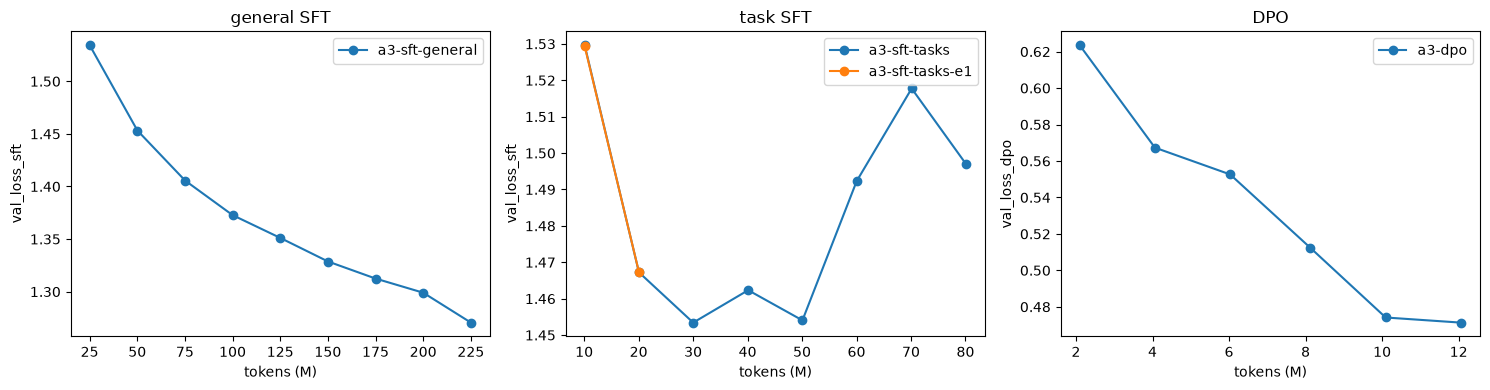

a3-sft-general done {'val_loss_sft': 1.2587}
a3-sft-tasks done {'val_loss_sft': 1.4945}
a3-sft-tasks-e1 done {'val_loss_sft': 1.4373}
a3-dpo done {'val_loss_dpo': 0.4717, 'val_pref_acc': 0.85}


In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, runs, key, title in ((axes[0], ['a3-sft-general'], 'val_loss_sft', 'general SFT'),
                             (axes[1], ['a3-sft-tasks', 'a3-sft-tasks-e1'], 'val_loss_sft', 'task SFT'),
                             (axes[2], ['a3-dpo'], 'val_loss_dpo', 'DPO')):
    for r in runs:
        if not (RUNS / r / 'metrics.jsonl').exists():
            continue
        ev = [m for m in metrics(r) if m['event'] == 'eval' and key in m and not m.get('final')]
        ax.plot([m['tokens'] / 1e6 for m in ev], [m[key] for m in ev], marker='o', label=r)
    ax.set_title(title); ax.set_xlabel('tokens (M)'); ax.set_ylabel(key); ax.legend()
plt.tight_layout(); plt.show()
for r in ('a3-sft-general', 'a3-sft-tasks', 'a3-sft-tasks-e1', 'a3-dpo'):
    if (RUNS / r / 'status.json').exists():
        s = load(RUNS / r / 'status.json')
        print(r, s['state'], {k: round(v, 4) for k, v in s.items() if k.startswith('val_') and isinstance(v, float)})

The 3-epoch task SFT reached its best validation loss after about one epoch and then rose: it
overfit the 1.3M task loss tokens. It was discarded and rerun at one epoch (`a3-sft-tasks-e1`),
which is the model DPO starts from.

## DPO pairs

In [4]:
ps = load(SFT / 'dpo_tasks' / 'pairs.stats.json')
print(json.dumps(ps['stats'], indent=1))
print('why our samples were rejected:'); print(json.dumps(ps['reasons'], indent=1, ensure_ascii=False))
pairs = [json.loads(l) for l in (SFT / 'dpo_tasks' / 'pairs.jsonl').read_text(encoding='utf-8').splitlines()]
for task in ('title', 'shownotes_reduce', 'relevance'):
    p = next((x for x in pairs if x['task'] == task), None)
    if p:
        print(f"\n=== {task} ({p['reason']}) ===\nCHOSEN  : {p['chosen'][:400]}\nREJECTED: {p['rejected'][:400]}")

{
 "train_relevance_pairs": 641,
 "train_relevance_passed": 359,
 "train_relevance_sampled": 1000,
 "train_shownotes_map_pairs": 4,
 "train_shownotes_map_passed": 996,
 "train_shownotes_map_sampled": 1000,
 "train_shownotes_reduce_pairs": 125,
 "train_shownotes_reduce_passed": 135,
 "train_shownotes_reduce_sampled": 260,
 "train_title_pairs": 405,
 "train_title_passed": 595,
 "train_title_sampled": 1000,
 "val_relevance_pairs": 64,
 "val_relevance_passed": 36,
 "val_relevance_sampled": 100,
 "val_shownotes_map_pairs": 2,
 "val_shownotes_map_passed": 98,
 "val_shownotes_map_sampled": 100,
 "val_shownotes_reduce_pairs": 7,
 "val_shownotes_reduce_passed": 8,
 "val_shownotes_reduce_sampled": 15,
 "val_title_pairs": 31,
 "val_title_passed": 56,
 "val_title_sampled": 87
}
why our samples were rejected:
{
 "relevance: disagrees with teacher (spearman #)": 685,
 "title: too long": 434,
 "shownotes_reduce: invalid draft (# usable tags, need #)": 76,
 "shownotes_reduce: invalid draft (# usable t

## 5. Samples (greedy, fixed prompts, as the trainer writes them)

In [5]:
for r in ('a3-sft-general', 'a3-sft-tasks-e1', 'a3-dpo'):
    p = RUNS / r / 'samples.md'
    if p.exists():
        last = p.read_text(encoding='utf-8').split('\n## ')[-1]
        print(f'##### {r} — {last[:1500]}\n')

##### a3-sft-general — step 1862 · 0.24B tokens

- **<|im_start|>user
¿Cuál es la capital de Francia?<|im_end|>
<|im_start|>assistant
**ParísAAAAA la capital de Francia.A la capital de Francia.A la capital de Francia.A la capital de Francia.
- **<|im_start|>user
Dame tres consejos para empezar un podcast.<|im_end|>
<|im_start|>assistant
**1. Establece un horario: Establece un horario para tu podcast y establece un horario para que los oyentes se conecten con tu contenido. Esto te ayudará a mantener el enfoque y la calidad de tu contenido.

2. Crea un espacio de trabajo: Crea un espacio de trabajo donde los oyentes puedan trabajar y compartir sus ideas. Esto puede incluir un espacio para grabar, editar y editar, y un espacio para editar y editar.

3. Crea un espacio
- **<|im_start|>user
Explain in one sentence what a podcast is.<|im_end|>
<|im_start|>assistant
**A podcast is a type of digital audio recording that allows users to create and edit audio content from their own devices, allo

## Conclusions

- General SFT turned the base model into one that follows the ChatML turn structure and answers in
  the asked language, with heavy repetition (val loss 1.534 → 1.259 over one epoch).
- Task SFT: one epoch is the right length for 1.3M task loss tokens (val 1.437); three overfit.
- DPO on 1,509 verifier-built pairs: val DPO loss 0.692 → 0.472, preference accuracy 0.85 on 20 val
  pairs. Its effect on the app's tools is measured in notebook 07: show notes improve, relevance does not.